# 4. Exploratory analysis

**Mục tiêu:** mô tả dữ liệu chất lượng không khí *sau khi làm sạch* (Phần 3) bằng thống kê mô tả,
phân tích **theo nhóm** (thành phố, mùa, giờ trong ngày, ngày trong tuần, năm) và 5 biểu đồ chính (headline charts).

> Notebook này tách riêng khỏi `main.ipynb` để không xung đột khi merge.
> Dữ liệu sạch được lấy từ cache `data/processed/station_hour_clean.pkl`;
> nếu chưa có cache, notebook tự chạy `main.ipynb` (Phần 0–3) rồi lưu cache lại.

## 4.0. Chuẩn bị dữ liệu

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 50)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')
FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_FILE = PROCESSED / 'station_hour_clean.pkl'

POLLUTANTS = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
              'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
KEY_POLLUTANTS = ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3']
BUCKETS = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
BUCKET_COLORS = ['#2E9E4F', '#9ACD32', '#F2C94C', '#F2994A', '#EB5757', '#8B1E3F']


def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')

In [2]:
# Lấy dữ liệu đã làm sạch (output của Phần 3 trong main.ipynb)
if CLEAN_FILE.exists():
    df_clean = pd.read_pickle(CLEAN_FILE)
    print('Đọc cache:', CLEAN_FILE)
else:
    print('Chưa có cache -> chạy main.ipynb (Phần 0-3), có thể mất vài phút...')
    get_ipython().run_line_magic('run', './main.ipynb')
    keep = ['StationId', 'Datetime'] + POLLUTANTS + ['AQI', 'AQI_calculated', 'AQI_bucket_calculated']
    df_clean = df[keep].copy()
    PROCESSED.mkdir(parents=True, exist_ok=True)
    df_clean.to_pickle(CLEAN_FILE)
    print('Đã lưu cache:', CLEAN_FILE)

stations = pd.read_csv(RAW / 'stations.csv')

data = df_clean.merge(stations[['StationId', 'StationName', 'City', 'State']],
                      on='StationId', how='left')
data['Datetime'] = pd.to_datetime(data['Datetime'])
data['Date'] = data['Datetime'].dt.normalize()
data['Year'] = data['Datetime'].dt.year
data['Month'] = data['Datetime'].dt.month
data['Hour'] = data['Datetime'].dt.hour
data['IsWeekend'] = data['Datetime'].dt.dayofweek >= 5

# Mùa theo Cục Khí tượng Ấn Độ (IMD)
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Summer', 4: 'Summer', 5: 'Summer',
              6: 'Monsoon', 7: 'Monsoon', 8: 'Monsoon', 9: 'Monsoon',
              10: 'Post-monsoon', 11: 'Post-monsoon'}
SEASONS = ['Winter', 'Summer', 'Monsoon', 'Post-monsoon']
data['Season'] = pd.Categorical(data['Month'].map(season_map), categories=SEASONS, ordered=True)

print(f"Số dòng (station-hour): {len(data):,}")
print(f"Số trạm: {data['StationId'].nunique()} | Số thành phố: {data['City'].nunique()} | Số bang: {data['State'].nunique()}")
print(f"Khoảng thời gian: {data['Datetime'].min()} -> {data['Datetime'].max()}")

Đọc cache: ..\data\processed\station_hour_clean.pkl


Số dòng (station-hour): 2,589,083


Số trạm: 110 | Số thành phố: 26 | Số bang: 21
Khoảng thời gian: 2015-01-01 01:00:00 -> 2020-07-01 00:00:00


## 4.1. Thống kê mô tả tổng thể

Thống kê cho từng chất ô nhiễm và AQI tính lại (`AQI_calculated`) trên toàn bộ station-hour sau làm sạch.
`missing_%` là tỷ lệ ô còn trống sau impute (các đoạn thiếu dài > 30% chuỗi được giữ nguyên NaN).

In [3]:
num_cols = POLLUTANTS + ['AQI_calculated']
desc = data[num_cols].describe(percentiles=[.25, .5, .75, .95]).T
desc['skew'] = data[num_cols].skew()
desc['missing_%'] = data[num_cols].isna().mean() * 100
desc = desc.rename(columns={'count': 'n', '50%': 'median'})
desc[['n', 'missing_%', 'mean', 'std', 'min', '25%', 'median', '75%', '95%', 'max', 'skew']]

,n,missing_%,mean,std,min,25%,median,75%,95%,max,skew
PM2.5,"2,361,447.00",8.79,77.58,80.73,0.01,29.09,52.25,93.50,237.00,999.83,2.97
PM10,"1,743,068.00",32.68,154.30,133.63,0.01,64.06,114.00,198.11,424.96,999.96,2.04
NO,"2,488,318.00",3.89,21.42,44.79,0.01,3.27,7.29,17.98,93.06,500.00,5.01
NO2,"2,505,400.00",3.23,34.78,33.10,0.01,13.60,24.95,45.00,96.87,499.99,2.93
NOx,"2,506,145.00",3.20,41.43,53.40,0.00,13.34,24.43,46.75,139.60,500.00,3.62
NH3,"1,599,324.00",38.23,28.26,26.62,0.01,11.12,21.98,37.25,72.35,499.97,3.85
CO,"2,505,861.00",3.21,1.56,5.12,0.00,0.49,0.86,1.43,3.85,490.35,28.66
SO2,"2,264,287.00",12.54,11.98,14.00,0.01,4.39,8.21,14.38,34.17,199.96,4.61
O3,"2,231,286.00",13.82,38.12,47.07,0.01,11.75,25.11,48.72,109.65,997.00,5.44
Benzene,"2,052,561.00",20.72,3.41,11.14,0.00,0.27,1.27,3.48,11.80,498.07,22.10


**Nhận xét 4.1:**
- Mọi chất đều **lệch phải mạnh** (skew > 2; CO và Benzene > 20): mean luôn lớn hơn median (PM2.5: mean 77.6 vs median 52.3 µg/m³). Vì vậy các so sánh nhóm phía sau ưu tiên dùng **trung vị**.
- PM2.5 trung vị 52 µg/m³ đã gần chuẩn 24h của Ấn Độ (60) và gấp ~3.5 lần hướng dẫn WHO 2021 (15). 25% số giờ có PM2.5 > 93.5.
- Sau làm sạch vẫn còn thiếu nhiều ở **Xylene (76%)**, NH3 (38%), PM10 (33%) → không dùng Xylene cho phân tích; PM10 phải đọc kèm số trạm có đo.
- AQI tính lại: trung vị 127 (mức *Moderate*); **31% station-hour ở mức Poor trở lên** (Poor 11.6%, Very Poor 14.4%, Severe 5.2%), chỉ 7% ở mức Good.
- AQI max = 3,084 do công thức ngoại suy tuyến tính khi nồng độ vượt breakpoint cuối (Phần 3). Chỉ 1.7% số giờ có AQI > 500 nên không ảnh hưởng tới trung vị.

In [4]:
# Phân bố AQI_bucket_calculated trên toàn bộ station-hour
bucket_share = (data['AQI_bucket_calculated']
                .value_counts(normalize=True)
                .reindex(BUCKETS) * 100)
bucket_share.to_frame('Tỷ lệ station-hour (%)')

,Tỷ lệ station-hour (%)
AQI_bucket_calculated,
Good,6.95
Satisfactory,27.88
Moderate,33.89
Poor,11.61
Very Poor,14.44
Severe,5.22


In [5]:
# Độ phủ dữ liệu: số trạm có số liệu AQI theo từng năm
coverage = (data.dropna(subset=['AQI_calculated'])
            .groupby('Year')
            .agg(n_stations=('StationId', 'nunique'),
                 n_cities=('City', 'nunique'),
                 station_hours=('AQI_calculated', 'size')))
coverage

,n_stations,n_cities,station_hours
Year,,,
2015,24,8,148449
2016,25,9,194530
2017,48,16,292513
2018,77,18,603423
2019,101,23,767658
2020,109,26,457601


**Độ phủ dữ liệu không đồng đều theo thời gian:** số trạm tăng từ 24 (2015, 8 thành phố) lên 109 (2020, 26 thành phố); năm 2020 chỉ có dữ liệu đến 1/7. Do đó **không nên so sánh trực tiếp con số tổng của các năm** — thay đổi giữa các năm một phần là do thay đổi mạng lưới trạm (xem 4.2.4).

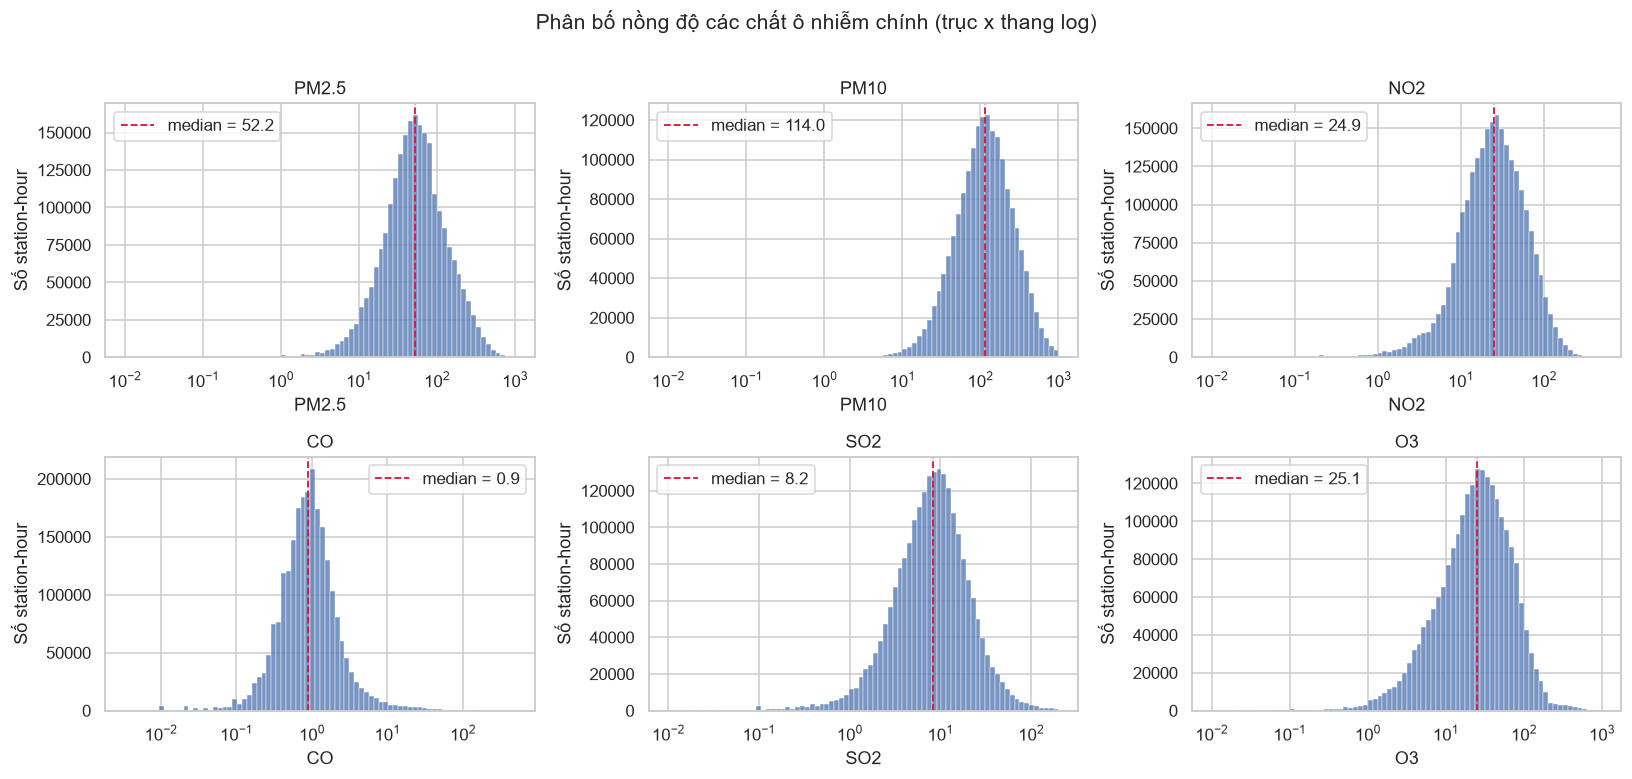

In [6]:
# Phân bố của các chất chính (thang log vì dữ liệu lệch phải mạnh)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, KEY_POLLUTANTS):
    s = data[col].dropna()
    s = s[s > 0]
    sns.histplot(s, bins=80, log_scale=True, ax=ax, color='#4C72B0')
    ax.axvline(s.median(), color='crimson', ls='--', lw=1.2, label=f'median = {s.median():.1f}')
    ax.set_title(col)
    ax.set_ylabel('Số station-hour')
    ax.legend()
fig.suptitle('Phân bố nồng độ các chất ô nhiễm chính (trục x thang log)', fontsize=14, y=1.01)
plt.tight_layout()
save(fig, 'supp_distribution')
plt.show()

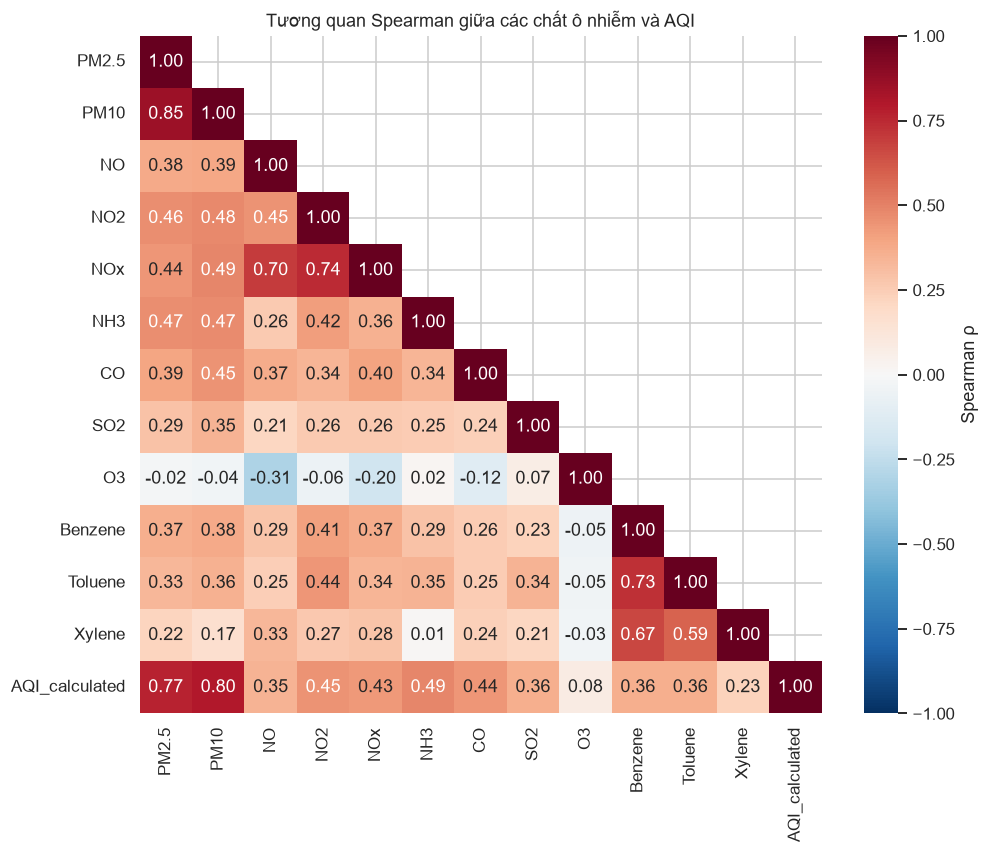

In [7]:
# Tương quan Spearman giữa các chất (không giả định phân phối chuẩn)
corr = data[POLLUTANTS + ['AQI_calculated']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax,
            cbar_kws={'label': 'Spearman ρ'})
ax.set_title('Tương quan Spearman giữa các chất ô nhiễm và AQI')
save(fig, 'supp_correlation')
plt.show()

**Tương quan (Spearman):** PM2.5–PM10 rất mạnh (ρ = 0.85, cùng là bụi); NO–NOx (0.70), NO2–NOx (0.74) và nhóm BTX Benzene–Toluene (0.73) cũng mạnh vì cùng nguồn đốt nhiên liệu. AQI tương quan mạnh nhất với **PM10 (0.80) và PM2.5 (0.77)**, các chất khí chỉ ở mức 0.35–0.49 → **bụi là chất chi phối AQI** ở phần lớn trạm. O3 gần như không tương quan với các chất khác và tương quan âm với NO (−0.31) vì NO phản ứng tiêu thụ O3 — phù hợp với chu kỳ ngày ngược pha ở Chart 4.

## 4.2. Phân tích theo nhóm (group-wise)

Không chỉ nhìn con số tổng thể, ta so sánh theo **thành phố**, **mùa**, **giờ trong ngày**, **ngày thường / cuối tuần** và **năm**.

Để mỗi trạm có trọng số ngang nhau theo thời gian, AQI được tổng hợp về **AQI ngày của từng trạm** (trung bình các giờ trong ngày,
chỉ giữ ngày có ≥ 16/24 giờ có số liệu — cùng ngưỡng với rolling 24h ở Phần 3).

In [8]:
daily = (data.groupby(['StationId', 'City', 'State', 'Date'], observed=True)
         .agg(AQI=('AQI_calculated', 'mean'),
              n_hours=('AQI_calculated', 'count'),
              **{c: (c, 'mean') for c in KEY_POLLUTANTS})
         .reset_index())
daily = daily[daily['n_hours'] >= 16].copy()
daily['Bucket'] = pd.cut(daily['AQI'], bins=[-np.inf, 50, 100, 200, 300, 400, np.inf], labels=BUCKETS)
daily['Year'] = daily['Date'].dt.year
daily['Month'] = daily['Date'].dt.month
daily['Season'] = pd.Categorical(daily['Month'].map(season_map), categories=SEASONS, ordered=True)
print(f'Số station-day hợp lệ: {len(daily):,}')

Số station-day hợp lệ: 102,666


### 4.2.1. Theo thành phố

In [9]:
city_stats = (daily.groupby('City')
              .agg(n_stations=('StationId', 'nunique'),
                   n_station_days=('AQI', 'size'),
                   AQI_mean=('AQI', 'mean'),
                   AQI_median=('AQI', 'median'),
                   PM25_mean=('PM2.5', 'mean'),
                   PM10_mean=('PM10', 'mean'),
                   NO2_mean=('NO2', 'mean'),
                   pct_poor_or_worse=('AQI', lambda s: (s > 200).mean() * 100),
                   pct_good_satisf=('AQI', lambda s: (s <= 100).mean() * 100))
              .sort_values('AQI_median', ascending=False))
city_stats

,n_stations,n_station_days,AQI_mean,AQI_median,PM25_mean,PM10_mean,NO2_mean,pct_poor_or_worse,pct_good_satisf
City,,,,,,,,,
Ahmedabad,1,2007,399.04,350.75,66.59,109.78,59.83,87.14,0.70
Delhi,37,41355,235.48,212.88,107.91,213.63,44.53,53.05,12.91
Lucknow,5,6088,213.84,190.38,105.74,NaN,34.18,48.29,22.85
Gurugram,4,2823,204.16,179.75,98.81,164.20,23.09,44.28,18.07
Patna,6,2662,195.77,154.81,94.71,116.42,37.59,38.28,23.18
Talcher,1,923,174.55,136.08,64.08,171.35,14.62,29.25,17.44
Jorapokhar,1,1167,149.34,128.17,62.95,145.14,9.25,18.08,16.88
Brajrajnagar,1,935,149.26,122.88,64.07,120.05,16.42,19.89,11.98
Bhopal,1,287,130.83,117.67,49.93,118.83,31.59,11.85,26.13


**Nhận xét theo thành phố:**
- Nhóm ô nhiễm nhất nằm ở **đồng bằng sông Hằng phía Bắc**: Delhi (AQI trung vị 213, 53% số ngày Poor trở lên), Lucknow (190), Gurugram (180), Patna (155). PM2.5 trung bình của 4 thành phố này đều ~95–108 µg/m³.
- Nhóm sạch nhất là các thành phố **ven biển phía Nam và vùng núi Đông Bắc**: Aizawl (27), Shillong (47), Thiruvananthapuram (66), Coimbatore (74) — gần như không có ngày Poor.
- Mumbai, Chennai, Bengaluru, Hyderabad (các đô thị lớn) có AQI trung vị ~84–91, thấp hơn Delhi khoảng **2.4 lần** dù quy mô dân số tương đương.
- Delhi chiếm 37/110 trạm và 40% số station-day → con số tổng thể toàn quốc bị kéo về phía Delhi; đây là lý do phải phân tích theo nhóm.

In [10]:
# Kiểm tra chất chi phối AQI: trung vị nồng độ theo thành phố (sắp xếp theo CO)
(data.groupby('City')[['CO', 'SO2', 'NO2', 'O3', 'PM2.5', 'PM10']]
     .median()
     .sort_values('CO', ascending=False)
     .head(8))

,CO,SO2,NO2,O3,PM2.5,PM10
City,,,,,,
Ahmedabad,8.93,44.30,44.50,26.74,56.45,102.39
Brajrajnagar,2.00,10.61,14.35,7.62,53.89,101.77
Talcher,1.76,26.63,9.78,8.95,49.41,136.63
Ernakulam,1.56,3.17,2.85,NaN,21.16,44.88
Kochi,1.29,17.86,12.14,1.44,26.93,48.08
Lucknow,1.12,6.19,25.75,28.04,80.43,NaN
Delhi,1.03,11.35,34.36,25.57,76.25,175.25
Patna,1.01,15.81,26.46,26.94,64.00,100.63


**Trường hợp Ahmedabad (đứng đầu Chart 1) cần thận trọng:** PM2.5 của Ahmedabad (66.6) thấp hơn Delhi (107.9), nhưng AQI lại cao nhất vì **CO trung vị 8.9 mg/m³, gấp ~9 lần Delhi (1.0)** và cao gấp 4 lần thành phố thứ hai. Với breakpoint CO (10 mg/m³ → AQI 200; 17 → 300), AQI của Ahmedabad gần như hoàn toàn do CO quyết định. Chỉ có **1 trạm** và mức CO này bất thường so với cả nước → nhiều khả năng là lỗi cảm biến/đơn vị đo. Nhóm đưa vào phần *Limitations* thay vì kết luận Ahmedabad là thành phố ô nhiễm nhất.

### 4.2.2. Theo mùa

In [11]:
season_stats = (daily.groupby('Season', observed=True)
                .agg(AQI_mean=('AQI', 'mean'), AQI_median=('AQI', 'median'),
                     PM25_mean=('PM2.5', 'mean'), PM10_mean=('PM10', 'mean'),
                     NO2_mean=('NO2', 'mean'), O3_mean=('O3', 'mean'),
                     pct_poor_or_worse=('AQI', lambda s: (s > 200).mean() * 100)))
season_stats

,AQI_mean,AQI_median,PM25_mean,PM10_mean,NO2_mean,O3_mean,pct_poor_or_worse
Season,,,,,,,
Winter,240.56,224.00,121.35,208.69,44.16,38.94,53.73
Summer,155.47,129.92,60.95,143.26,31.50,44.62,25.80
Monsoon,112.56,92.96,39.33,97.03,24.66,30.58,10.01
Post-monsoon,229.23,191.83,114.60,204.62,43.43,40.54,48.89


In [12]:
# AQI trung vị theo mùa của từng thành phố (đo độ chênh mùa đông / mùa mưa)
city_season = daily.pivot_table(index='City', columns='Season', values='AQI',
                                aggfunc='median', observed=True)
city_season['Winter / Monsoon'] = city_season['Winter'] / city_season['Monsoon']
city_season.sort_values('Winter / Monsoon', ascending=False)

Season,Winter,Summer,Monsoon,Post-monsoon,Winter / Monsoon
City,,,,,
Guwahati,285.90,91.42,46.38,109.25,6.16
Kolkata,219.71,77.96,53.92,160.23,4.07
Patna,328.98,148.29,94.25,315.67,3.49
Lucknow,333.00,162.46,95.71,319.52,3.48
Talcher,291.71,125.29,105.67,151.42,2.76
Delhi,331.23,191.58,120.38,323.44,2.75
Gurugram,302.40,155.67,111.19,305.38,2.72
Mumbai,160.38,81.75,60.96,112.38,2.63
Hyderabad,121.83,94.73,52.71,106.58,2.31


**Nhận xét theo mùa:**
- Mùa **đông (12–2)** ô nhiễm nặng nhất: AQI trung vị 224, PM2.5 trung bình 121 µg/m³, **54% số ngày Poor trở lên**. Mùa **mưa (6–9)** sạch nhất: AQI 93, PM2.5 39, chỉ 10% số ngày Poor. Chênh lệch PM2.5 đông/mưa ≈ **3.1 lần**.
- Post-monsoon (10–11) gần như ngang mùa đông (AQI 192) — trùng với thời điểm đốt rơm rạ sau thu hoạch và lễ Diwali ở phía Bắc.
- Mức chênh mùa khác nhau rất lớn giữa các thành phố: Guwahati (6.2 lần), Kolkata (4.1), Patna/Lucknow (3.5), Delhi (2.8) dao động mạnh; trong khi Chennai, Coimbatore (~1.0) gần như không đổi theo mùa — do khí hậu ven biển nhiệt đới ít nghịch nhiệt.

### 4.2.3. Ngày thường và cuối tuần

In [13]:
wk = (data.groupby('IsWeekend')[KEY_POLLUTANTS + ['AQI_calculated']].mean().T
      .rename(columns={False: 'Weekday', True: 'Weekend'}))
wk['Chênh lệch (%)'] = (wk['Weekend'] / wk['Weekday'] - 1) * 100
wk

IsWeekend,Weekday,Weekend,Chênh lệch (%)
PM2.5,78.16,76.14,-2.59
PM10,155.67,150.87,-3.09
NO2,35.12,33.92,-3.40
CO,1.56,1.53,-1.90
SO2,12.01,11.90,-0.96
O3,38.09,38.18,0.23
AQI_calculated,175.55,172.70,-1.62


**Ngày thường vs cuối tuần:** chênh lệch rất nhỏ — PM2.5 cuối tuần thấp hơn 2.6%, NO2 thấp hơn 3.4%, AQI thấp hơn 1.6%; O3 gần như không đổi (+0.2%). Hiệu ứng cuối tuần **yếu**, cho thấy nguồn ô nhiễm chính (nền khí hậu, công nghiệp, đốt sinh khối) không giảm vào cuối tuần; giao thông chỉ đóng góp một phần.

### 4.2.4. Theo năm

In [14]:
# Lưu ý: số trạm tăng mạnh theo năm nên chênh lệch giữa các năm một phần do thay đổi mạng lưới trạm
yearly_all = daily.groupby('Year').agg(n_stations=('StationId', 'nunique'),
                                       AQI_median=('AQI', 'median'),
                                       PM25_mean=('PM2.5', 'mean'),
                                       NO2_mean=('NO2', 'mean'))
yearly_all

,n_stations,AQI_median,PM25_mean,NO2_mean
Year,,,,
2015,24,172.92,85.18,31.83
2016,25,141.79,89.21,37.45
2017,47,130.12,86.56,36.84
2018,77,143.17,85.51,37.47
2019,101,126.44,76.20,34.95
2020,107,109.46,57.36,27.33


**Theo năm:** PM2.5 trung bình ổn định ~85–89 µg/m³ giai đoạn 2015–2018, giảm còn 76 (2019) và **57 (2020)**. Tuy nhiên năm 2020 chỉ có nửa đầu năm (thiếu mùa đông cuối năm) và có lockdown COVID-19, đồng thời số trạm tăng 24 → 107 (nhiều trạm mới ở các thành phố sạch hơn ở phía Nam). Vì vậy xu hướng giảm này **chưa đủ cơ sở** để kết luận chất lượng không khí cải thiện; Chart 5 so sánh công bằng hơn bằng cách cố định trạm và cố định giai đoạn.

## 4.3. Năm biểu đồ chính (Headline charts)

| # | Câu hỏi | Biểu đồ |
|---|---------|---------|
| 1 | Thành phố nào ô nhiễm nhất / sạch nhất? | Boxplot AQI ngày theo thành phố |
| 2 | Bao nhiêu phần trăm số ngày không khí ở mức kém trở lên? | Stacked bar tỷ lệ AQI bucket theo thành phố |
| 3 | Ô nhiễm thay đổi theo mùa như thế nào? | Heatmap PM2.5 thành phố × tháng |
| 4 | Ô nhiễm thay đổi trong ngày ra sao? | Đường trung bình theo giờ (PM2.5, NO2, CO, O3) |
| 5 | Lockdown COVID-19 2020 ảnh hưởng thế nào? | So sánh 25/3–31/5 năm 2020 với 2019 theo thành phố |

Tất cả biểu đồ được lưu vào `reports/figures/` để chèn vào báo cáo.

### Chart 1 — Phân bố AQI ngày theo thành phố

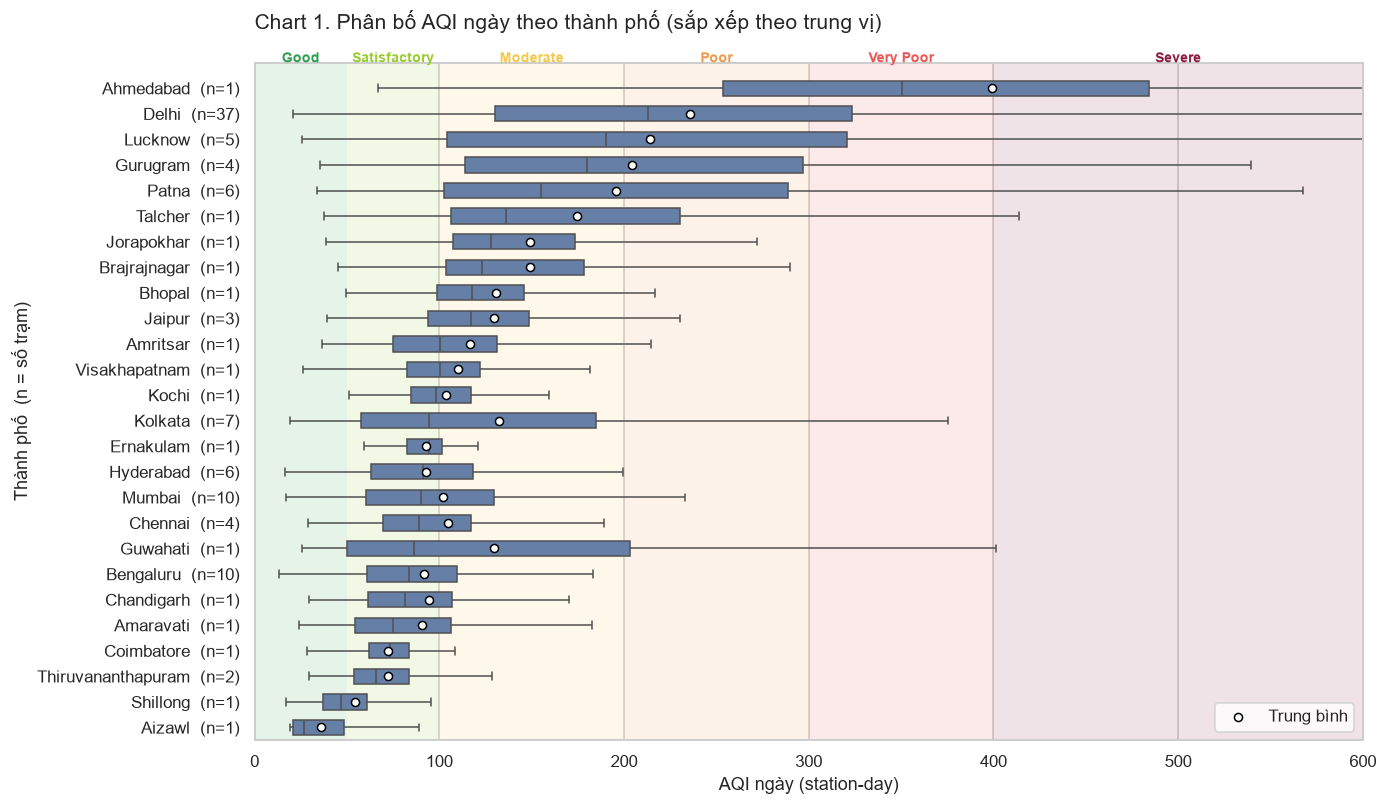

In [15]:
order = city_stats.index.tolist()
fig, ax = plt.subplots(figsize=(13, 8))

# Nền màu theo ngưỡng AQI của Ấn Độ
edges = [0, 50, 100, 200, 300, 400, 600]
for lo, hi, c, b in zip(edges[:-1], edges[1:], BUCKET_COLORS, BUCKETS):
    ax.axvspan(lo, hi, color=c, alpha=0.12, lw=0)
    ax.text((lo + hi) / 2, -0.9, b, ha='center', va='bottom', fontsize=9, color=c, fontweight='bold')

sns.boxplot(data=daily, y='City', x='AQI', order=order, ax=ax, color='#5B7DB1',
            showfliers=False, width=0.6, linewidth=1)
means = daily.groupby('City')['AQI'].mean().reindex(order)
ax.scatter(means.values, range(len(order)), color='white', edgecolor='black', zorder=5, s=28, label='Trung bình')

labels = [f"{c}  (n={int(city_stats.loc[c, 'n_stations'])})" for c in order]
ax.set_yticks(range(len(order)), labels)
ax.set_xlim(0, 600)
ax.set_ylim(len(order) - 0.5, -1)
ax.set_xlabel('AQI ngày (station-day)')
ax.set_ylabel('Thành phố  (n = số trạm)')
ax.set_title('Chart 1. Phân bố AQI ngày theo thành phố (sắp xếp theo trung vị)',
             fontsize=14, loc='left', pad=22)
ax.legend(loc='lower right')
save(fig, 'chart1_aqi_by_city')
plt.show()

**Chart 1:** Ranh giới Bắc–Nam rất rõ. Hộp (IQR) của Delhi, Lucknow, Gurugram, Patna trải từ mức *Moderate* tới *Very Poor*, trong khi các thành phố phía Nam và Đông Bắc gần như nằm gọn trong vùng *Good–Satisfactory–Moderate*. Các thành phố phía Bắc còn có **độ phân tán lớn** (IQR ~190 điểm ở Delhi) do tính mùa vụ mạnh. Ahmedabad đứng đầu nhưng do CO bất thường (xem 4.2.1).

### Chart 2 — Tỷ lệ số ngày theo mức AQI của từng thành phố

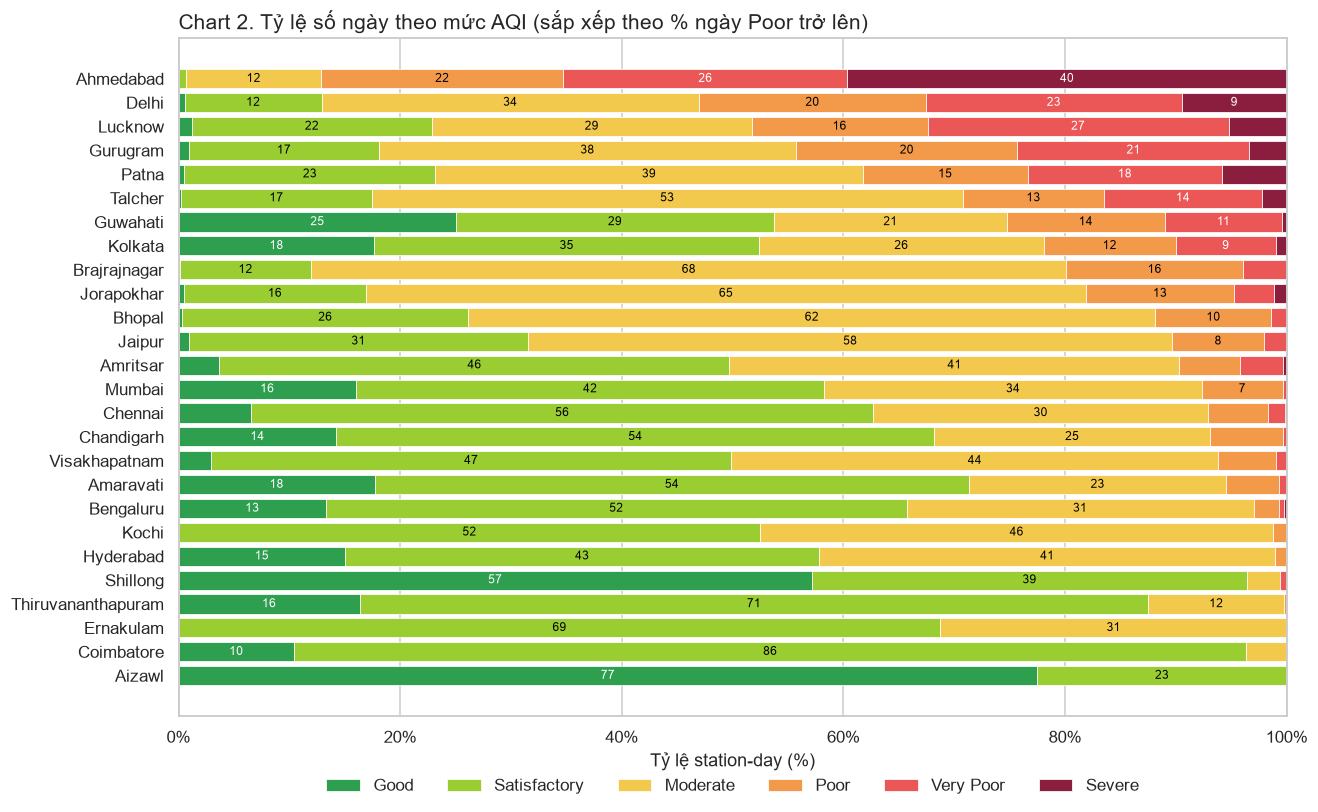

In [16]:
share = (pd.crosstab(daily['City'], daily['Bucket'], normalize='index') * 100).reindex(columns=BUCKETS)
share = share.loc[(share['Poor'] + share['Very Poor'] + share['Severe']).sort_values().index]

fig, ax = plt.subplots(figsize=(13, 8))
left = np.zeros(len(share))
for b, c in zip(BUCKETS, BUCKET_COLORS):
    ax.barh(share.index, share[b], left=left, color=c, label=b, edgecolor='white', linewidth=0.5)
    for i, (v, l) in enumerate(zip(share[b], left)):
        if v >= 7:
            ax.text(l + v / 2, i, f'{v:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if b in ('Very Poor', 'Severe', 'Good') else 'black')
    left += share[b].to_numpy()

ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.set_xlabel('Tỷ lệ station-day (%)')
ax.set_title('Chart 2. Tỷ lệ số ngày theo mức AQI (sắp xếp theo % ngày Poor trở lên)', fontsize=14, loc='left')
ax.legend(ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.07), frameon=False)
save(fig, 'chart2_aqi_bucket_share')
plt.show()

**Chart 2:** Ở Delhi chỉ **13% số ngày** đạt mức Good/Satisfactory và **53% số ngày** ở mức Poor trở lên (Very Poor 23%, Severe 9%). Ngược lại, Aizawl và Shillong có > 95% số ngày Good/Satisfactory. Kolkata và Guwahati có phân bố "hai cực": nhiều ngày Good nhưng cũng có 20–25% ngày Poor trở lên (tập trung vào mùa đông).

### Chart 3 — Tính mùa vụ của PM2.5

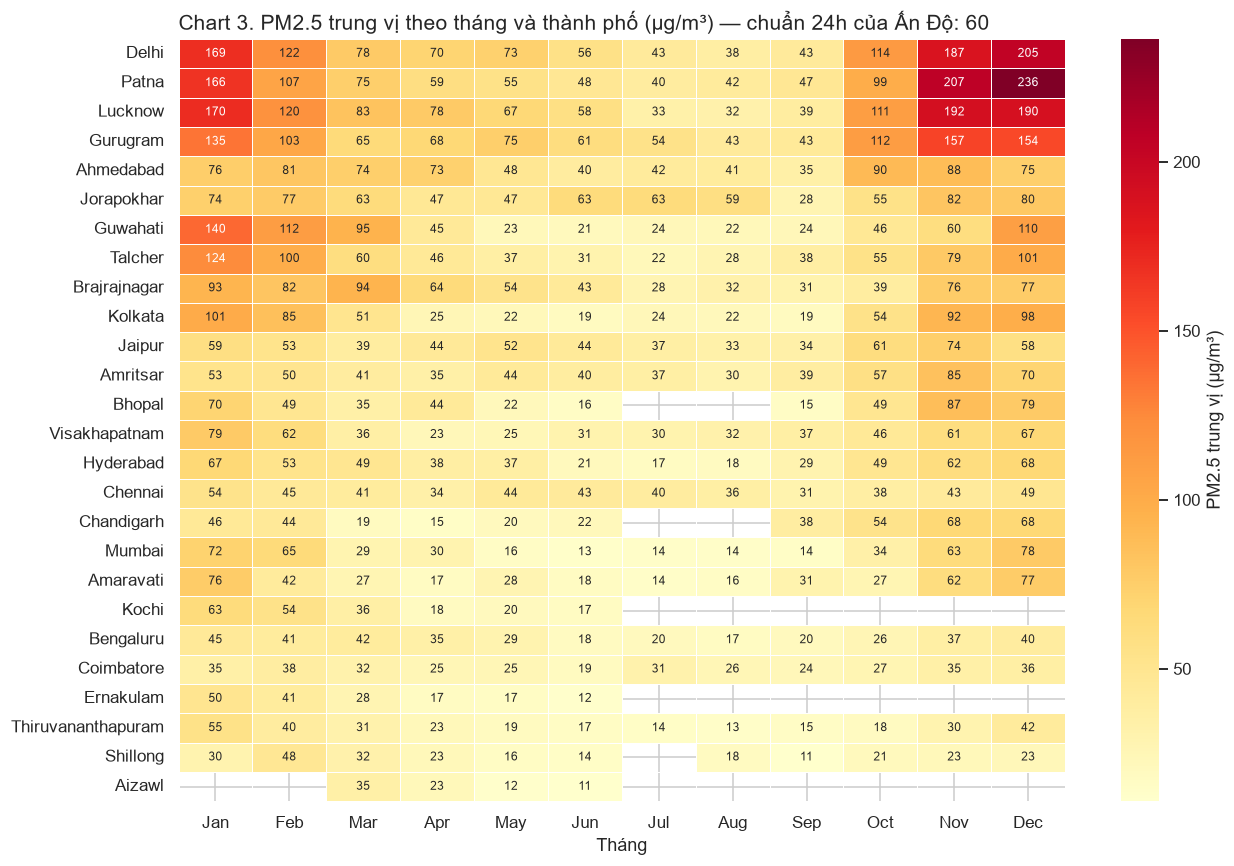

In [17]:
month_city = daily.pivot_table(index='City', columns='Month', values='PM2.5', aggfunc='median')
month_city = month_city.loc[month_city.mean(axis=1).sort_values(ascending=False).index]
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(month_city, cmap='YlOrRd', annot=True, fmt='.0f', annot_kws={'size': 8},
            linewidths=0.4, linecolor='white', cbar_kws={'label': 'PM2.5 trung vị (µg/m³)'}, ax=ax)
ax.set_xticklabels(month_names)
ax.set_xlabel('Tháng')
ax.set_ylabel('')
ax.set_title('Chart 3. PM2.5 trung vị theo tháng và thành phố (µg/m³) — chuẩn 24h của Ấn Độ: 60', fontsize=14, loc='left')
save(fig, 'chart3_pm25_month_city')
plt.show()

**Chart 3:** Mẫu hình chữ U theo tháng xuất hiện ở hầu hết các thành phố: đỉnh vào **tháng 11–1**, đáy vào **tháng 7–9**. Ở Delhi, Patna, Lucknow PM2.5 trung vị tháng 12 đạt **190–236 µg/m³, gấp 3–4 lần chuẩn 24h (60)**, trong khi tháng 8 chỉ ~32–42. Các thành phố phía Nam (Bengaluru, Coimbatore, Chennai) có màu nhạt quanh năm. Ô trống là các tháng trạm chưa có dữ liệu (trạm mở mới năm 2020).

### Chart 4 — Chu kỳ trong ngày

Mỗi chất được chuẩn hoá bằng trung bình của chính nó (giá trị = 1 nghĩa là bằng mức trung bình ngày),
để so sánh hình dạng chu kỳ của các chất có đơn vị khác nhau.

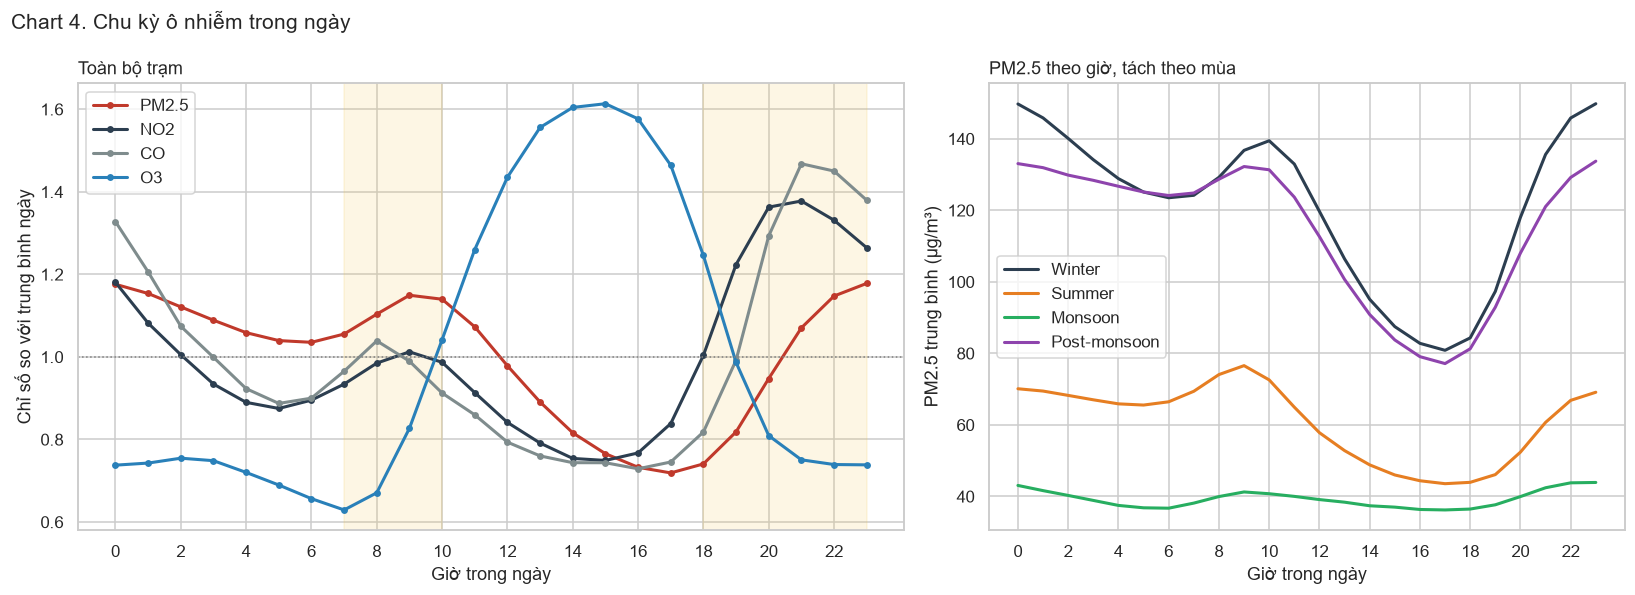

In [18]:
hourly = data.groupby('Hour')[['PM2.5', 'NO2', 'CO', 'O3']].mean()
hourly_idx = hourly / hourly.mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
colors = {'PM2.5': '#C0392B', 'NO2': '#2C3E50', 'CO': '#7F8C8D', 'O3': '#2980B9'}
for col in hourly_idx:
    axes[0].plot(hourly_idx.index, hourly_idx[col], marker='o', ms=3.5, lw=2, label=col, color=colors[col])
axes[0].axhline(1, color='grey', ls=':', lw=1)
axes[0].axvspan(7, 10, color='#F2C94C', alpha=0.15)
axes[0].axvspan(18, 23, color='#F2C94C', alpha=0.15)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel('Giờ trong ngày')
axes[0].set_ylabel('Chỉ số so với trung bình ngày')
axes[0].set_title('Toàn bộ trạm', loc='left')
axes[0].legend()

# PM2.5 theo giờ, tách theo mùa
hs = data.groupby(['Season', 'Hour'], observed=True)['PM2.5'].mean().unstack(0)
season_colors = {'Winter': '#2C3E50', 'Summer': '#E67E22', 'Monsoon': '#27AE60', 'Post-monsoon': '#8E44AD'}
for s in SEASONS:
    axes[1].plot(hs.index, hs[s], lw=2, label=s, color=season_colors[s])
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel('Giờ trong ngày')
axes[1].set_ylabel('PM2.5 trung bình (µg/m³)')
axes[1].set_title('PM2.5 theo giờ, tách theo mùa', loc='left')
axes[1].legend()

fig.suptitle('Chart 4. Chu kỳ ô nhiễm trong ngày', fontsize=14, x=0.01, ha='left')
plt.tight_layout()
save(fig, 'chart4_diurnal')
plt.show()

In [19]:
pd.DataFrame({'Giờ cao nhất': hourly.idxmax(), 'Giờ thấp nhất': hourly.idxmin(),
              'Cao nhất / thấp nhất': hourly.max() / hourly.min()})

,Giờ cao nhất,Giờ thấp nhất,Cao nhất / thấp nhất
PM2.5,23,17,1.64
NO2,21,15,1.84
CO,21,16,2.01
O3,15,7,2.56


**Chart 4:**
- PM2.5, NO2, CO có **hai đỉnh**: buổi sáng (8–10h, giờ đi làm) và lớn hơn vào **buổi tối – đêm (20–23h)**; thấp nhất vào 15–17h. Đỉnh đêm lớn hơn đỉnh sáng vì ngoài giao thông còn có **lớp khí quyển biên thấp về đêm** giữ chất ô nhiễm lại gần mặt đất.
- O3 ngược pha hoàn toàn: đỉnh 15h, thấp nhất 7h (cao gấp 2.6 lần) — vì O3 là chất ô nhiễm thứ cấp hình thành nhờ ánh nắng.
- Biên độ ngày của PM2.5 lớn nhất vào **mùa đông** (~150 µg/m³ lúc nửa đêm vs ~80 lúc 17h) và gần như phẳng vào mùa mưa → giờ ra ngoài tốt nhất trong mùa đông là buổi chiều.

### Chart 5 — Lockdown COVID-19 (25/3 – 31/5/2020)

Ấn Độ phong toả toàn quốc từ 25/3/2020. So sánh trung bình PM2.5 và NO2 của **cùng giai đoạn 25/3–31/5**
năm 2020 với năm 2019, **chỉ trên các trạm có số liệu ở cả hai năm** (≥ 30 ngày mỗi năm) để so sánh công bằng.

In [20]:
def lockdown_window(d, year):
    return d[(d['Date'] >= f'{year}-03-25') & (d['Date'] <= f'{year}-05-31')]

w19 = lockdown_window(daily, 2019)
w20 = lockdown_window(daily, 2020)
ok19 = w19.groupby('StationId').size().loc[lambda s: s >= 30].index
ok20 = w20.groupby('StationId').size().loc[lambda s: s >= 30].index
common = ok19.intersection(ok20)

agg_cols = ['PM2.5', 'NO2', 'AQI']
c19 = w19[w19['StationId'].isin(common)].groupby('City')[agg_cols].mean()
c20 = w20[w20['StationId'].isin(common)].groupby('City')[agg_cols].mean()
change = ((c20 / c19 - 1) * 100).dropna(subset=['PM2.5', 'NO2'])
change['n_stations'] = w20[w20['StationId'].isin(common)].groupby('City')['StationId'].nunique()
change = change.sort_values('NO2')

overall = {c: (w20[w20['StationId'].isin(common)][c].mean() /
               w19[w19['StationId'].isin(common)][c].mean() - 1) * 100 for c in agg_cols}
print(f'Số trạm so sánh được: {len(common)}')
print('Thay đổi tổng thể (2020 so với 2019):', {k: f'{v:+.1f}%' for k, v in overall.items()})
change.round(1)

Số trạm so sánh được: 76
Thay đổi tổng thể (2020 so với 2019): {'PM2.5': '-35.1%', 'NO2': '-41.1%', 'AQI': '-33.3%'}


,PM2.5,NO2,AQI,n_stations
City,,,,
Ahmedabad,-59.10,-66.50,-56.80,1
Lucknow,-38.00,-56.70,-42.50,3
Amaravati,-23.70,-55.80,-25.30,1
Jaipur,-34.50,-51.40,-26.40,3
Delhi,-36.80,-45.80,-34.90,36
Chennai,-50.90,-44.20,-40.10,3
Bengaluru,-40.90,-40.90,-30.20,10
Kolkata,-32.20,-34.60,-17.20,2
Mumbai,39.40,-33.70,-21.00,1


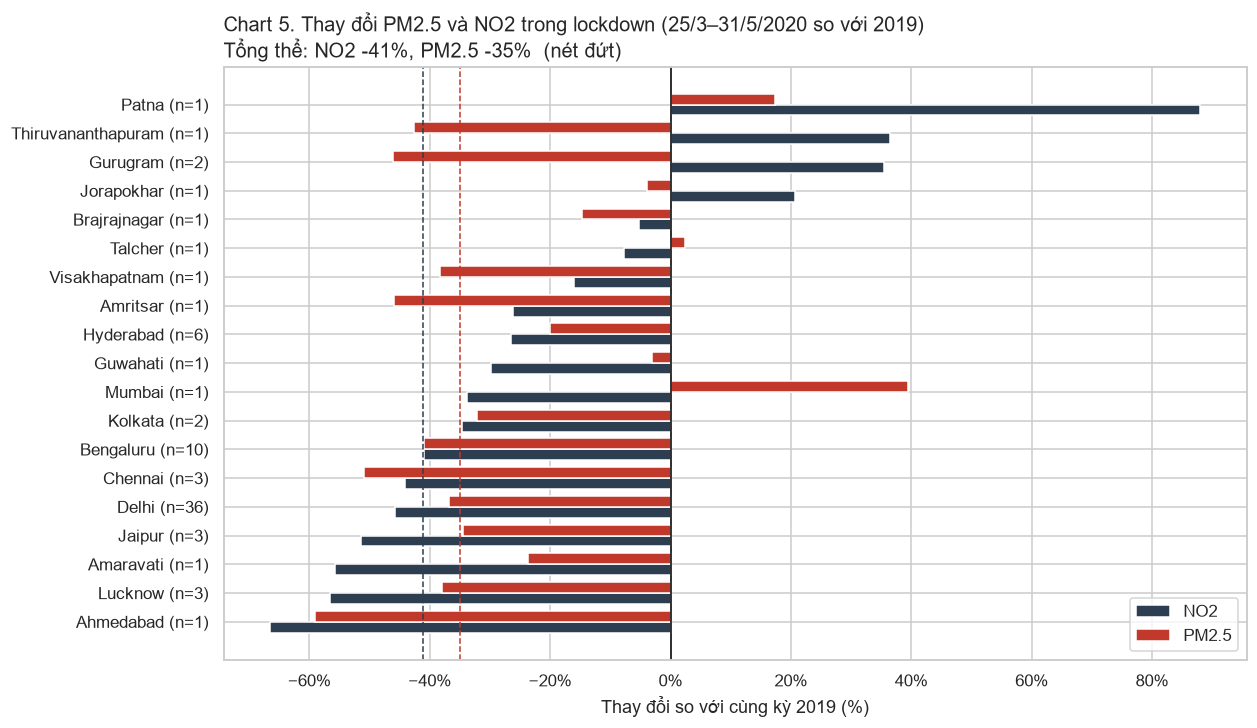

In [21]:
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(change))
h = 0.38
ax.barh(y - h / 2, change['NO2'], height=h, color='#2C3E50', label='NO2')
ax.barh(y + h / 2, change['PM2.5'], height=h, color='#C0392B', label='PM2.5')
ax.axvline(0, color='black', lw=1)
ax.axvline(overall['NO2'], color='#2C3E50', ls='--', lw=1)
ax.axvline(overall['PM2.5'], color='#C0392B', ls='--', lw=1)
ax.set_yticks(y, [f"{c} (n={int(n)})" for c, n in zip(change.index, change['n_stations'])])
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Thay đổi so với cùng kỳ 2019 (%)')
ax.set_title(f"Chart 5. Thay đổi PM2.5 và NO2 trong lockdown (25/3–31/5/2020 so với 2019)\n"
             f"Tổng thể: NO2 {overall['NO2']:+.0f}%, PM2.5 {overall['PM2.5']:+.0f}%  (nét đứt)",
             fontsize=13, loc='left')
ax.legend(loc='lower right')
save(fig, 'chart5_lockdown')
plt.show()

**Chart 5:** Trên 76 trạm có dữ liệu cả hai năm, giai đoạn lockdown 25/3–31/5/2020 có **NO2 giảm 41%, PM2.5 giảm 35%, AQI giảm 33%** so với cùng kỳ 2019. NO2 (chủ yếu từ giao thông) giảm mạnh nhất ở các đô thị lớn: Delhi −46%, Lucknow −57%, Jaipur −51%, Bengaluru −41%. Một số thành phố đi ngược xu hướng (Patna NO2 +88%, Mumbai PM2.5 +39%, Talcher, Jorapokhar) nhưng chỉ có **1–2 trạm** và các thành phố công nghiệp/khai mỏ (Talcher, Jorapokhar, Brajrajnagar) gần như không đổi — phù hợp với việc nguồn ô nhiễm ở đó là công nghiệp vẫn hoạt động, không phải giao thông.

## 4.4. Tóm tắt Phần 4

| # | Phát hiện | Biểu đồ |
|---|-----------|---------|
| 1 | Các thành phố **đồng bằng sông Hằng phía Bắc** (Delhi, Lucknow, Gurugram, Patna) ô nhiễm nặng nhất; AQI trung vị của Delhi (213) gấp ~2.4 lần Mumbai/Chennai/Bengaluru. | Chart 1 |
| 2 | Delhi có **53% số ngày** ở mức Poor trở lên và chỉ 13% số ngày Good/Satisfactory. | Chart 2 |
| 3 | Ô nhiễm mang **tính mùa vụ mạnh**: PM2.5 mùa đông gấp ~3 lần mùa mưa; ở phía Bắc PM2.5 tháng 12 gấp 3–4 lần chuẩn quốc gia. | Chart 3 |
| 4 | PM2.5/NO2/CO đạt đỉnh vào **20–23h** và 8–10h, thấp nhất 15–17h; O3 ngược pha (đỉnh 15h). | Chart 4 |
| 5 | Lockdown COVID-19 làm **NO2 giảm 41%, PM2.5 giảm 35%** so với cùng kỳ 2019 (76 trạm cố định), giao thông là nguồn quan trọng ở đô thị lớn. | Chart 5 |

**Lưu ý cho Phần 6 (Limitations):** AQI của Ahmedabad bị chi phối bởi CO bất thường (1 trạm); độ phủ trạm tăng mạnh theo năm và năm 2020 chỉ có nửa năm; Delhi chiếm ~40% số station-day; Xylene/NH3/PM10 còn thiếu nhiều; nhiều thành phố chỉ có 1 trạm nên không đại diện cho cả thành phố.